In [1]:
# IMPORTS

import rasterio
import geopandas as gpd
import pandas as pd
import numpy as np

from rasterio.mask import mask
from pathlib import Path
from tqdm import tqdm

import matplotlib.pyplot as plt

In [2]:
# ROOT

ROOT_DIR = Path("..")

# INPUT
INDICES_DIR = ROOT_DIR / "indices_aligned"

# AOI
CROP_BOUNDARY = (
    ROOT_DIR /
    "aoi" /
    "crop_boundary.gpkg"
)

# OUTPUT
OUTPUT_DIR = (
    ROOT_DIR /
    "outputs" /
    "temporal_analysis"
)

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

print("Folders ready.")


Folders ready.


In [3]:
# LOAD CROP BOUNDARY

crop_aoi = gpd.read_file(
    CROP_BOUNDARY
)

print(crop_aoi.head())

print("\nCrop AOI loaded.")

   area m2                                           geometry
0     2298  POLYGON ((354248.693 5789628.59, 354248.77 578...

Crop AOI loaded.


In [4]:
def calculate_crop_statistics(
    raster_path,
    crop_aoi
):

    with rasterio.open(raster_path) as src:

        # REPROJECT IF NEEDED
        if crop_aoi.crs != src.crs:

            crop_projected = (
                crop_aoi.to_crs(src.crs)
            )

        else:

            crop_projected = crop_aoi

        # MASK
        clipped, _ = mask(
            src,
            crop_projected.geometry,
            crop=True
        )

        data = clipped[0].astype("float32")

        # -----------------------------------------
        # REMOVE NODATA
        # -----------------------------------------

        nodata = src.nodata

        if nodata is not None:

            data = data[data != nodata]

        # REMOVE NAN
        data = data[np.isfinite(data)]

        # REMOVE EXTREME NEGATIVE VALUES
        data = data[data > -100]

        # REMOVE EXTREME POSITIVE VALUES
        data = data[data < 100]

        # CHECK EMPTY
        if len(data) == 0:

            return {
                "mean": np.nan,
                "std": np.nan,
                "min": np.nan,
                "max": np.nan
            }

        return {

            "mean": float(np.mean(data)),
            "std": float(np.std(data)),
            "min": float(np.min(data)),
            "max": float(np.max(data))
        }

In [5]:
def temporal_analysis():

    all_results = []

    # YEARS
    year_folders = sorted([
        f for f in INDICES_DIR.iterdir()
        if f.is_dir()
    ])

    for year_folder in year_folders:

        year_name = year_folder.name

        print(f"\nPROCESSING YEAR: {year_name}")

        # FLIGHTS
        flight_folders = sorted([
            f for f in year_folder.iterdir()
            if f.is_dir()
        ])

        for flight_folder in tqdm(flight_folders):

            flight_name = flight_folder.name

            date_string = (
                flight_name.replace(
                    "flight_",
                    ""
                )
            )

            tif_files = list(
                flight_folder.glob("*.tif")
            )

            for tif_path in tif_files:

                index_name = (
                    tif_path.stem
                    .replace(date_string + "_", "")
                )

                stats = calculate_crop_statistics(
                    tif_path,
                    crop_aoi
                )

                result = {

                    "year": year_name,
                    "date": date_string,
                    "index": index_name,

                    "mean": stats["mean"],
                    "std": stats["std"],
                    "min": stats["min"],
                    "max": stats["max"]
                }

                all_results.append(result)

    df = pd.DataFrame(all_results)

    # SAVE CSV
    csv_output = (
        OUTPUT_DIR /
        "temporal_statistics.csv"
    )

    df.to_csv(
        csv_output,
        index=False
    )

    print("\nCSV SAVED.")

    return df

In [6]:
df = temporal_analysis()

df.head()


PROCESSING YEAR: 2025


100%|██████████████████████████████████████████████████████████████████████████████████| 11/11 [00:22<00:00,  2.01s/it]



PROCESSING YEAR: 2026


100%|████████████████████████████████████████████████████████████████████████████████████| 9/9 [00:14<00:00,  1.63s/it]


CSV SAVED.


,year,date,index,mean,std,min,max
0,2025,2025_04_09,canopy_temperature,14.785665,1.636848,9.019533,18.060131
1,2025,2025_04_09,GNDVI,0.568705,0.053599,0.323522,0.904195
2,2025,2025_04_09,NDRE,0.230063,0.036277,-0.100232,0.748149
3,2025,2025_04_09,NDVI,0.592143,0.085594,0.271747,0.948616
4,2025,2025_05_08,canopy_temperature,25.130085,3.257638,16.391617,39.942135


In [7]:
def plot_temporal_trends(df):

    years = df["year"].unique()

    # INDICES TO PLOT TOGETHER
    vegetation_indices = [
        "NDVI",
        "NDRE",
        "GNDVI"
    ]

    for year in years:

        # =====================================================
        # PLOT 1 -> VEGETATION INDICES
        # =====================================================

        plt.figure(figsize=(12, 6))

        year_df = df[
            df["year"] == year
        ].copy()

        # CONVERT DATE
        year_df["date"] = pd.to_datetime(
            year_df["date"],
            format="%Y_%m_%d"
        )

        for index_name in vegetation_indices:

            subset = year_df[
                year_df["index"] == index_name
            ].sort_values("date")

            plt.plot(
                subset["date"],
                subset["mean"],
                marker="o",
                label=index_name
            )

        plt.title(
            f"Vegetation Indices Trend {year}"
        )

        plt.xlabel("Date")

        plt.ylabel("Mean Index Value")

        plt.legend()

        plt.grid(True)

        output_plot = (
            OUTPUT_DIR /
            f"{year}_vegetation_indices.png"
        )

        plt.savefig(
            output_plot,
            dpi=300,
            bbox_inches="tight"
        )

        plt.show()

        print(
            f"Saved plot: {output_plot.name}"
        )

        # =====================================================
        # PLOT 2 -> CANOPY TEMPERATURE
        # =====================================================

        plt.figure(figsize=(12, 6))

        thermal_subset = year_df[
            year_df["index"] == "canopy_temperature"
        ].sort_values("date")

        plt.plot(
            thermal_subset["date"],
            thermal_subset["mean"],
            marker="o"
        )

        plt.title(
            f"Canopy Temperature Trend {year}"
        )

        plt.xlabel("Date")

        plt.ylabel("Mean Temperature (°C)")

        plt.grid(True)

        output_plot = (
            OUTPUT_DIR /
            f"{year}_canopy_temperature.png"
        )

        plt.savefig(
            output_plot,
            dpi=300,
            bbox_inches="tight"
        )

        plt.show()

        print(
            f"Saved plot: {output_plot.name}"
        )

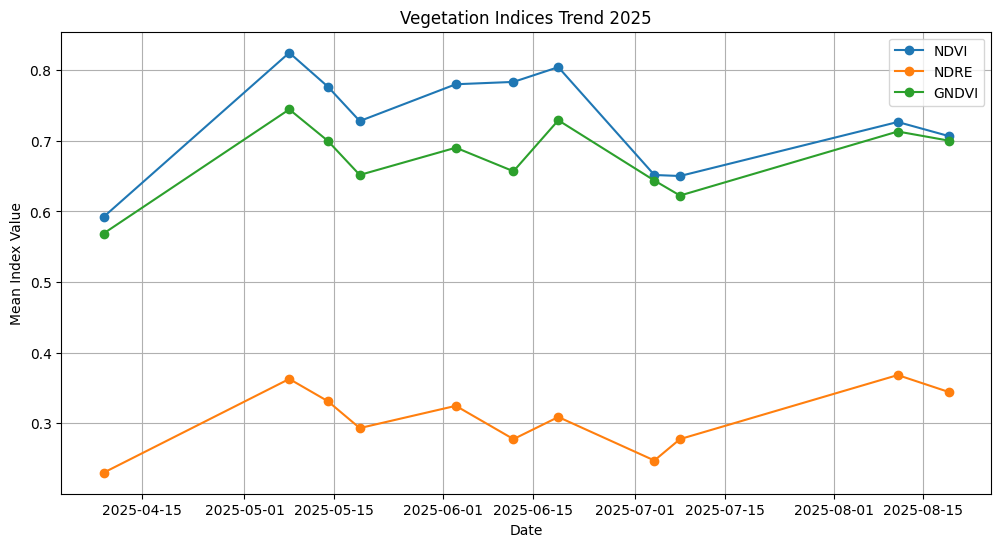

Saved plot: 2025_vegetation_indices.png


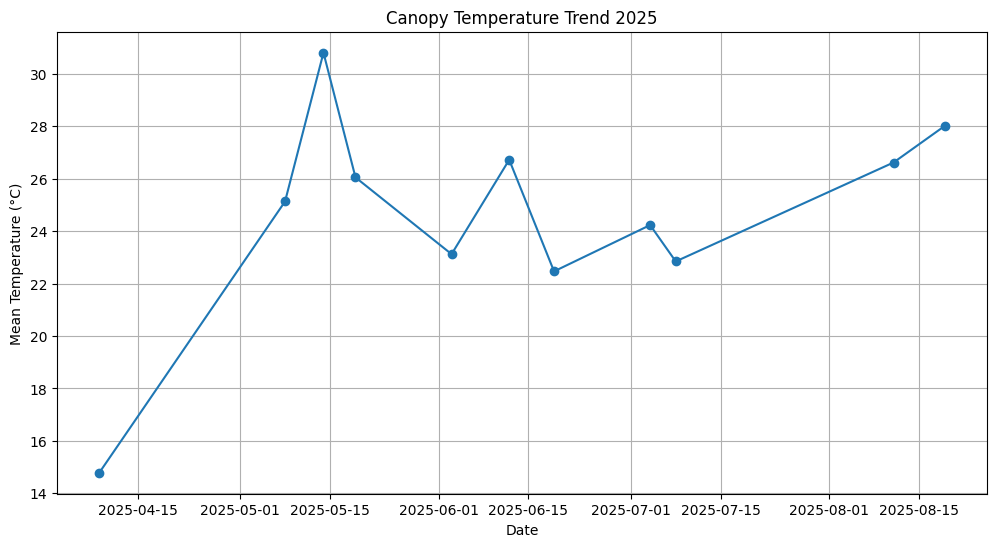

Saved plot: 2025_canopy_temperature.png


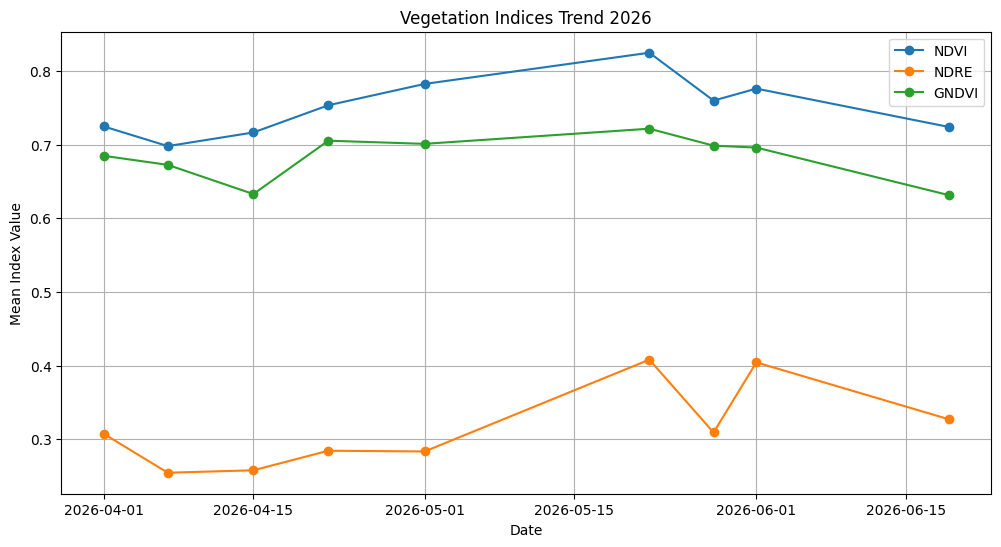

Saved plot: 2026_vegetation_indices.png


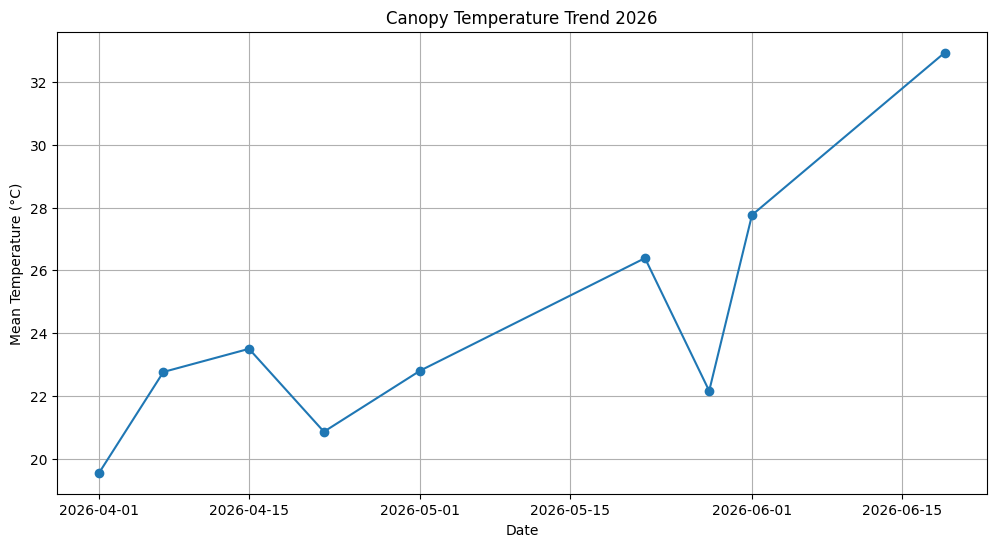

Saved plot: 2026_canopy_temperature.png


In [8]:
plot_temporal_trends(df)